# I 2. Some Basic Concepts of the Theory of Sets

Apostol, *Calculus*, Vol. 1 (2nd ed.), Introduction, Part 2: Sections I 2.1–I 2.5, pp. 11–15.

*Last updated: 24 October 2026*

## Scope

This part introduces the language of sets that the rest of the book uses. The notebook restates the notions in short
form, illustrates membership, inclusion and the set operations with small examples, and solves the exercises of
Section I 2.5, checking the answers with code where a computation is possible.

| Section | Topic | Page | In this notebook |
|---|---|---|---|
| I 2.1 | Introduction to set theory | 11 | notes |
| I 2.2 | Notations for designating sets | 12 | Figure 1 |
| I 2.3 | Subsets | 12 | Figure 2 |
| I 2.4 | Unions, intersections, complements | 13 | Figure 3 |
| I 2.5 | Exercises | 15 | Exercises 1–20, Figures 4–5 |

Each figure is drawn once with fixed values and saved in `figures/`; these are the images shown on GitHub and in the
HTML file. The controls under a figure redraw it for other values when the notebook is run in Jupyter.

In [1]:
import sys
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Image, display
from ipywidgets import Dropdown, FloatSlider, Text, interact
from matplotlib.patches import Ellipse

ROOT = next(p for p in Path.cwd().resolve().parents if (p / "apostol").is_dir())
sys.path.insert(0, str(ROOT))

from apostol.sets import cover_relations, inclusions, is_proper_subset, power_set, roster
from apostol.style import BAND, BLUE, INK, MUTED, free_axis, may_touch, save_figure, use_style, value_axis

use_style()


def show_figure(name, draw, heading):
    # Save the figure in figures/ (checked for the axis rule and for overlapping text) and show the saved file.
    display(Image(filename=str(save_figure(name, draw, heading)), width=620))


def parse_set(text):
    # "2, 4, 6" -> {2, 4, 6}
    return {int(t) for t in text.replace(" ", "").split(",") if t}

## I 2.1 Introduction to set theory

Set theory, developed mainly by George Boole and Georg Cantor in the second half of the nineteenth century, gives
analysis, algebra and geometry a common language. The book does not develop it axiomatically; it uses a few basic
notions as a working language. A **set** is a collection of objects regarded as a single whole, and the objects are its
**elements** (or members). We write $x \in S$ when $x$ is an element of $S$ and $x \notin S$ when it is not. The
elements may be numbers, points, curves or any other objects; a set about whose elements nothing particular is
assumed is an *abstract* set.

## I 2.2 Notations for designating sets

Sets are usually denoted by capital letters $A, B, C, \dots$ and elements by small letters $a, b, c, \dots$. A set can
be given by listing its elements between braces (roster notation): the positive even integers less than $10$ form
$\{2, 4, 6, 8\}$, and all positive even integers form $\{2, 4, 6, \dots\}$, the dots meaning that the pattern goes on.

Two sets are **equal**, $A = B$, when they have exactly the same elements. Hence neither the order in which the
elements are listed nor repetitions matter: $\{2, 4, 6, 8\} = \{8, 6, 4, 2\} = \{2, 2, 4, 4, 6, 8\}$.

Figure 1 sorts the integers $0, \dots, 20$ by membership in $S = \{2, 4, 6, 8\}$, and the cell checks the two rules
of equality with Python sets.

{2, 4, 6, 8} == {8, 6, 4, 2}:       True
{2, 4, 6, 8} == {2, 2, 4, 4, 6, 8}: True
distinct letters of 'mississippi':  {i, m, p, s}


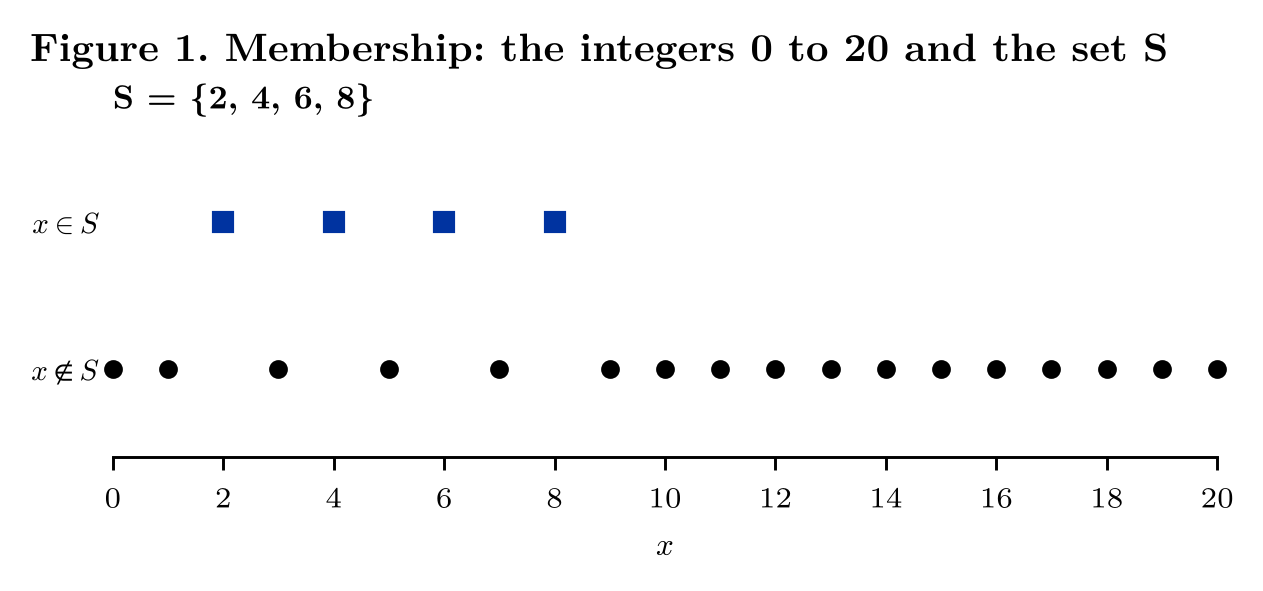

In [2]:
def draw_membership(S=frozenset({2, 4, 6, 8}), candidates=range(0, 21)):
    inside = [x for x in candidates if x in S]
    outside = [x for x in candidates if x not in S]
    fig, ax = plt.subplots(figsize=(4.75, 1.4))
    ax.plot(inside, [1] * len(inside), "s", color=BLUE, ms=4.5, label="in S", clip_on=False)
    ax.plot(outside, [0] * len(outside), "o", color=INK, ms=3.5, label="not in S", clip_on=False)
    lo, hi = min(candidates), max(candidates)
    value_axis(ax, "x", lo - lo % 2, hi + hi % 2, 2)
    ax.set_ylim(-0.6, 1.6)
    ax.set_yticks([0, 1], ["$x \\notin S$", "$x \\in S$"])
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    free_axis(ax, "y")
    ax.set_xlabel("$x$")
    ax.set_title(f"S = {roster(S)}")
    return fig


print("{2, 4, 6, 8} == {8, 6, 4, 2}:      ", {2, 4, 6, 8} == {8, 6, 4, 2})
print("{2, 4, 6, 8} == {2, 2, 4, 4, 6, 8}:", {2, 4, 6, 8} == {2, 2, 4, 4, 6, 8})
print("distinct letters of 'mississippi': ", roster(set("mississippi")))
show_figure("fig1_membership", draw_membership, "Figure 1. Membership: the integers 0 to 20 and the set S")

In [3]:
@interact(S=Text(value="2, 4, 6, 8", description="S"))
def explore_membership(S):
    draw_membership(frozenset(x for x in parse_set(S) if 0 <= x <= 20))
    plt.show()

interactive(children=(Text(value='2, 4, 6, 8', description='S'), Output()), _dom_classes=('widget-interact',))

## I 2.3 Subsets

A set $A$ is a **subset** of $B$, written $A \subseteq B$, when every element of $A$ is also an element of $B$. Equality
is inclusion in both directions:

$$
A = B \iff A \subseteq B \ \text{and}\ B \subseteq A .
$$

If $A \subseteq B$ but $A \ne B$, then $A$ is a **proper subset** of $B$, written $A \subset B$.

Usually a **universal set** $S$ is fixed and only its subsets are considered. The set of elements of $S$ with a
property $P$ is written $\{x \mid x \in S \text{ and } x \text{ satisfies } P\}$, or $\{x \mid P(x)\}$ when $S$ is
understood; for example $\{x \mid x > 0\}$ is the set of positive real numbers. The letter $x$ is a dummy variable:
$\{x \mid x > 0\} = \{t \mid t > 0\}$.

The **empty set** $\varnothing$ has no elements and is a subset of every set. An element $x$ and the one-element set
$\{x\}$ are different objects; in particular $\varnothing \ne \{\varnothing\}$, since the first set has no element and
the second has one.

Figure 2 takes the universal set $U = \{1, \dots, 12\}$, the set $B$ of its even numbers, the subset $A = \{4, 8\}$ of
$B$, and the set $P$ of multiples of 3 defined by a property. The four rows split $U$ into disjoint parts.

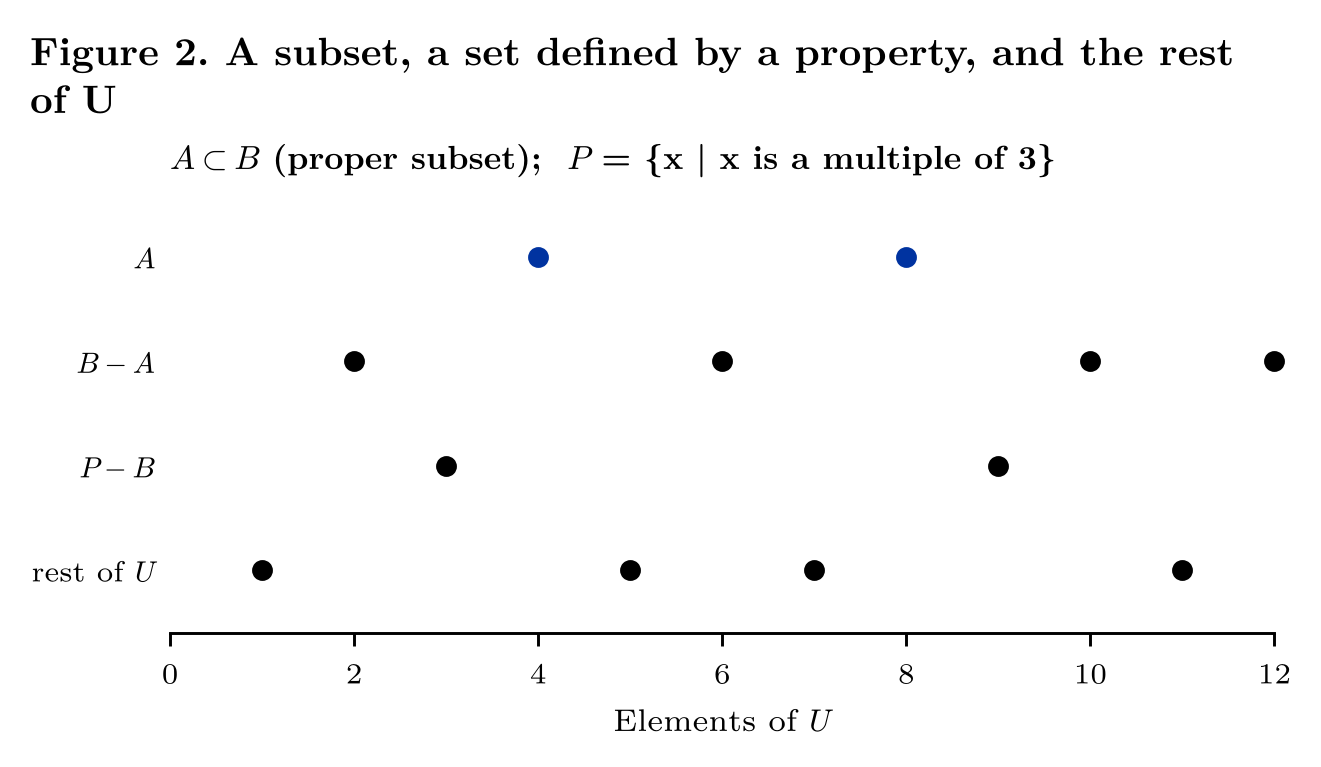

In [4]:
PROPERTIES = {"x is a multiple of 3": lambda x: x % 3 == 0, "x is a multiple of 4": lambda x: x % 4 == 0,
              "x is even": lambda x: x % 2 == 0, "x > 6": lambda x: x > 6}


def draw_subsets(U=frozenset(range(1, 13)), A=frozenset({4, 8}), B=frozenset({2, 4, 6, 8, 10, 12}),
                 prop="x is a multiple of 3"):
    U, A, B = set(U), set(A) & set(U), set(B) & set(U)
    P = {x for x in U if PROPERTIES[prop](x)}
    rows = [("$A$", A), ("$B - A$", B - A), ("$P - B$", P - B), ("rest of $U$", U - (A | B | P))]
    fig, ax = plt.subplots(figsize=(4.75, 1.9))
    for y, (_, part) in zip(range(3, -1, -1), rows):
        xs = sorted(part)
        ax.plot(xs, [y] * len(xs), "o", color=BLUE if y == 3 else INK, ms=4, clip_on=False)
    value_axis(ax, "x", 0, 12, 2)
    ax.set_ylim(-0.6, 3.6)
    ax.set_yticks(range(3, -1, -1), [name for name, _ in rows])
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    free_axis(ax, "y")
    ax.set_xlabel("Elements of $U$")
    relation = ("$A \\subset B$ (proper subset)" if is_proper_subset(A, B) else "$A \\subseteq B$" if A <= B
                else "$A$ is not a subset of $B$")
    ax.set_title(f"{relation};  $P$ = {{x | {prop}}}")
    return fig


show_figure("fig2_subsets", draw_subsets, "Figure 2. A subset, a set defined by a property, and the rest of U")

In [5]:
@interact(A=Text(value="4, 8", description="A"), B=Text(value="2, 4, 6, 8, 10, 12", description="B"),
          prop=Dropdown(options=list(PROPERTIES), description="P"))
def explore_subsets(A, B, prop):
    draw_subsets(A=frozenset(parse_set(A)), B=frozenset(parse_set(B)), prop=prop)
    plt.show()

interactive(children=(Text(value='4, 8', description='A'), Text(value='2, 4, 6, 8, 10, 12', description='B'), …

## I 2.4 Unions, intersections, complements

From two sets $A$ and $B$ three new sets are formed:

$$
A \cup B = \{x \mid x \in A \text{ or } x \in B\}, \qquad
A \cap B = \{x \mid x \in A \text{ and } x \in B\}, \qquad
A - B = \{x \mid x \in A \text{ and } x \notin B\}.
$$

The union contains the elements in at least one of the sets, the intersection those in both; if $A \cap B =
\varnothing$ the sets are **disjoint**. The difference $A - B$ is the complement of $B$ relative to $A$.

Union and intersection are commutative and associative,

$$
A \cup B = B \cup A, \quad A \cap B = B \cap A, \quad (A \cup B) \cup C = A \cup (B \cup C), \quad
(A \cap B) \cap C = A \cap (B \cap C),
$$

so that $A_1 \cup \cdots \cup A_n$ and $A_1 \cap \cdots \cap A_n$ need no parentheses. For a nonempty family
$\mathcal{F}$ of sets, $\bigcup_{A \in \mathcal{F}} A$ is the set of elements that belong to at least one member of
$\mathcal{F}$, and $\bigcap_{A \in \mathcal{F}} A$ the set of elements that belong to every member.

Figure 3 draws the three situations as diagrams: the shaded region is $A \cup B$ in (a) and $A \cap B$ in (b); in (c)
the sets are disjoint.

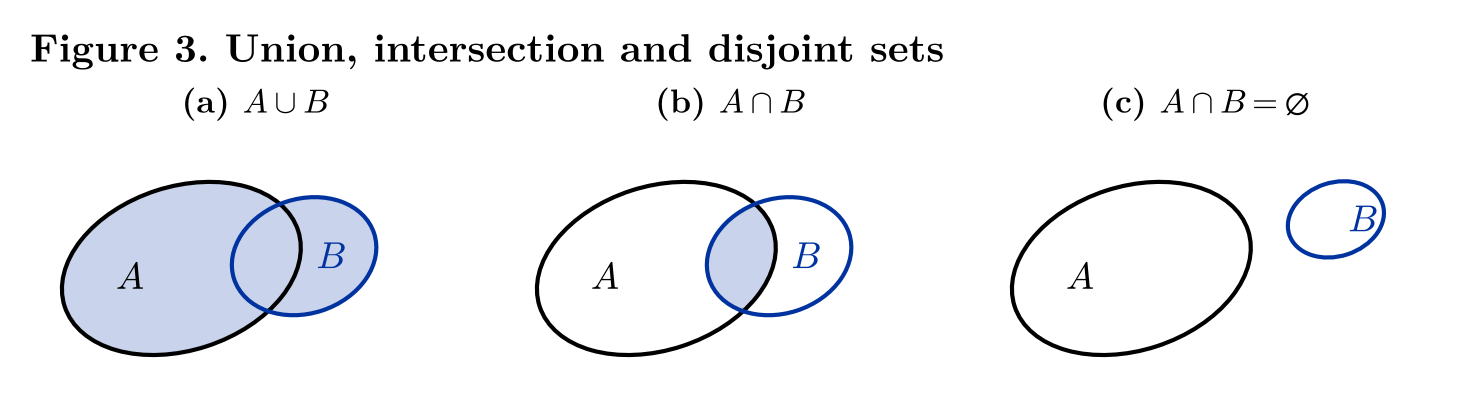

In [6]:
def ellipse(center, width, height, **kw):
    return Ellipse(center, width, height, angle=18, **kw)


def draw_venn(dx=0.0, dy=0.0):
    a_c, b_c = (4.2, 3.1), (7.2 + dx, 3.4 + dy)
    a_size, b_size = (6.0, 4.0), (3.6, 2.8)
    fig, axes = plt.subplots(1, 3, figsize=(4.75, 1.75), constrained_layout=True)
    for ax, mode, title in zip(axes, ("union", "intersection", "disjoint"),
                               ("(a) $A \\cup B$", "(b) $A \\cap B$", "(c) $A \\cap B = \\varnothing$")):
        bc = b_c if mode != "disjoint" else (9.2 + dx, 4.3 + dy)
        bs = b_size if mode != "disjoint" else (2.4, 1.8)
        if mode == "union":
            ax.add_patch(ellipse(a_c, *a_size, facecolor=BAND, edgecolor="none"))
            ax.add_patch(ellipse(bc, *bs, facecolor=BAND, edgecolor="none"))
        elif mode == "intersection":
            outline_a = ellipse(a_c, *a_size, facecolor="none", edgecolor="none")
            ax.add_patch(outline_a)
            shaded = ellipse(bc, *bs, facecolor=BAND, edgecolor="none")
            ax.add_patch(shaded)
            shaded.set_clip_path(outline_a)
        ax.add_patch(ellipse(a_c, *a_size, facecolor="none", edgecolor=INK, lw=1.0))
        ax.add_patch(ellipse(bc, *bs, facecolor="none", edgecolor=BLUE, lw=1.0))
        ax.text(2.6, 2.6, "$A$", fontsize=9)
        ax.text(bc[0] + 0.3, bc[1] - 0.3, "$B$", fontsize=9, color=BLUE)
        ax.set_xlim(0.5, 11.5)
        ax.set_ylim(0.3, 6.3)
        ax.set_aspect("equal")
        ax.set_axis_off()
        ax.set_title(title, loc="center")
    return fig


show_figure("fig3_union_intersection", draw_venn, "Figure 3. Union, intersection and disjoint sets")

In [7]:
@interact(dx=FloatSlider(value=0.0, min=-3, max=2, step=0.1), dy=FloatSlider(value=0.0, min=-2, max=2, step=0.1))
def explore_venn(dx, dy):
    draw_venn(dx, dy)
    plt.show()

interactive(children=(FloatSlider(value=0.0, description='dx', max=2.0, min=-3.0), FloatSlider(value=0.0, desc…

## I 2.5 Exercises (p. 15)

### Exercise 1

Write the following sets of real numbers in roster notation:

$$
A = \{x \mid x^2 - 1 = 0\}, \quad B = \{x \mid (x-1)^2 = 0\}, \quad C = \{x \mid x + 8 = 9\},
$$

$$
D = \{x \mid x^3 - 2x^2 + x = 2\}, \quad E = \{x \mid (x+8)^2 = 9^2\}, \quad F = \{x \mid (x^2 + 16x)^2 = 17^2\}.
$$

**Solution.**

- $A$: $x^2 = 1$, so $x = \pm 1$ and $A = \{-1, 1\}$.
- $B$: $x - 1 = 0$, so $B = \{1\}$.
- $C$: $x = 1$, so $C = \{1\}$.
- $D$: $x^3 - 2x^2 + x - 2 = x^2(x-2) + (x-2) = (x-2)(x^2+1) = 0$; since $x^2 + 1 > 0$ for real $x$, $D = \{2\}$.
- $E$: $x + 8 = \pm 9$, so $E = \{-17, 1\}$.
- $F$: $x^2 + 16x = \pm 17$. From $x^2 + 16x - 17 = (x+17)(x-1) = 0$ we get $x = -17, 1$; from $x^2 + 16x + 17 = 0$,
  $x = -8 \pm \sqrt{47}$. Hence $F = \{-17,\ -8-\sqrt{47},\ -8+\sqrt{47},\ 1\}$.

The cell below solves each equation over the real numbers with SymPy and plots the six sets on the real line.

A = {-1, 1}
B = {1}
C = {1}
D = {2}
E = {-17, 1}
F = {-17, -8 - sqrt(47), -8 + sqrt(47), 1}


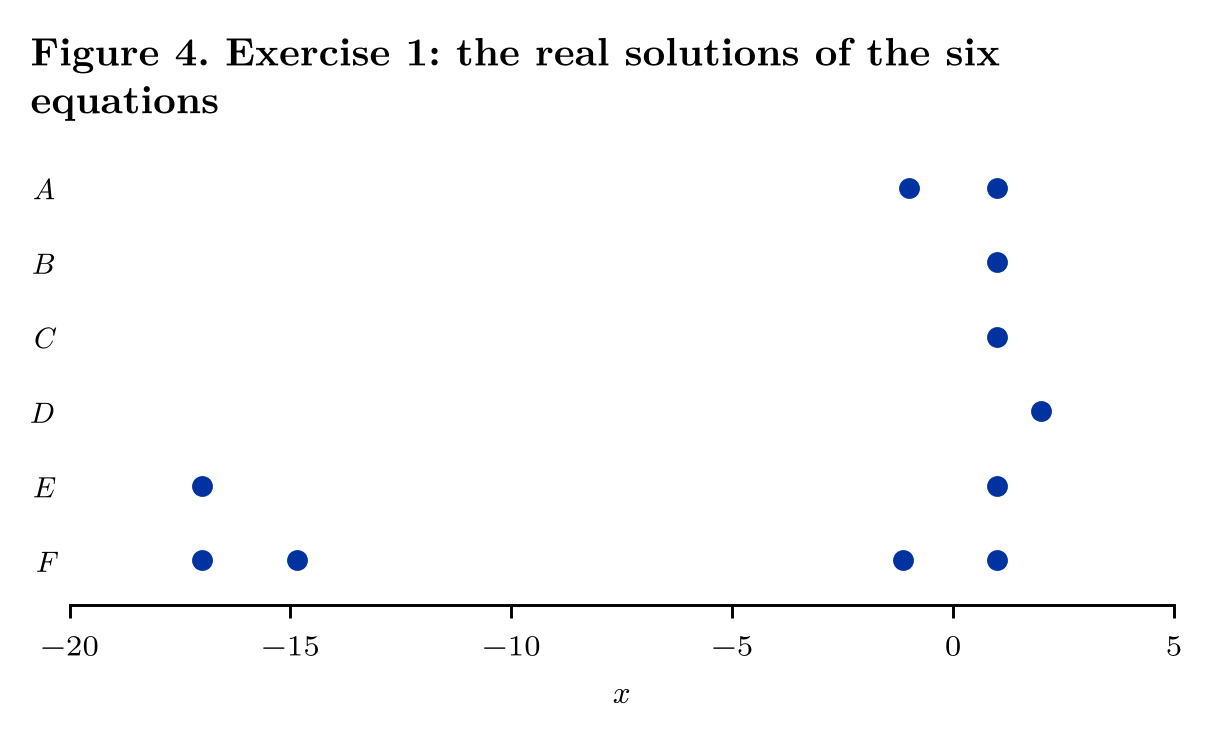

In [8]:
x = sp.symbols("x", real=True)
EQUATIONS = {"A": sp.Eq(x**2 - 1, 0), "B": sp.Eq((x - 1)**2, 0), "C": sp.Eq(x + 8, 9),
             "D": sp.Eq(x**3 - 2 * x**2 + x, 2), "E": sp.Eq((x + 8)**2, 9**2), "F": sp.Eq((x**2 + 16 * x)**2, 17**2)}
SETS = {name: set(sp.solveset(eq, x, domain=sp.S.Reals)) for name, eq in EQUATIONS.items()}
for name, s in SETS.items():
    print(f"{name} = {roster(s, fmt=sp.sstr)}")


def draw_exercise1():
    fig, ax = plt.subplots(figsize=(4.75, 2.0))
    names = list(SETS)
    for y, name in zip(range(len(names) - 1, -1, -1), names):
        xs = [float(v) for v in SETS[name]]
        ax.plot(xs, [y] * len(xs), "o", color=BLUE, ms=4)
    value_axis(ax, "x", -20, 5, 5)
    ax.set_ylim(-0.6, len(names) - 0.4)
    ax.set_yticks(range(len(names) - 1, -1, -1), [f"${n}$" for n in names])
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    free_axis(ax, "y")
    ax.set_xlabel("$x$")
    return fig


show_figure("fig4_exercise1", draw_exercise1, "Figure 4. Exercise 1: the real solutions of the six equations")

### Exercise 2

For the sets of Exercise 1, $B \subseteq A$. List all the inclusion relations $\subseteq$ among $A, B, C, D, E, F$.

**Solution.** Besides the trivial relations $X \subseteq X$:

$$
B \subseteq A, \quad C \subseteq A, \quad B \subseteq C, \quad C \subseteq B, \quad B \subseteq E, \quad
C \subseteq E, \quad B \subseteq F, \quad C \subseteq F, \quad E \subseteq F .
$$

$B = C = \{1\}$, so each is contained in the other; $B$ and $C$ are contained in $A$, $E$ and $F$; $E \subseteq F$; and
$D = \{2\}$ is contained in no other set. The code compares every pair and also lists the cover relations (proper
inclusions with no set strictly between), which are the edges of a Hasse diagram.

In [9]:
for X, Y in inclusions(SETS):
    print(f"{X} ⊆ {Y}")
print("\ncover relations:", ", ".join(f"{X} ⊂ {Y}" for X, Y in cover_relations(SETS)))

B ⊆ A
B ⊆ C
B ⊆ E
B ⊆ F
C ⊆ A
C ⊆ B
C ⊆ E
C ⊆ F
E ⊆ F

cover relations: B ⊂ A, B ⊂ E, C ⊂ A, C ⊂ E, E ⊂ F


### Exercises 3 and 4

Take (Exercise 3) $A = \{1\}$, $B = \{1, 2\}$ and (Exercise 4) $A = \{1\}$, $B = \{1, \{1\}\}$, and decide which
statements hold: (a) $A \subset B$, (b) $A \subseteq B$, (c) $A \in B$, (d) $1 \in A$, (e) $1 \subseteq A$,
(f) $1 \subset B$.

**Solution.**

| Statement | Exercise 3: $B = \{1, 2\}$ | Exercise 4: $B = \{1, \{1\}\}$ |
|---|---|---|
| (a) $A \subset B$ | true: $1 \in B$ and $A \ne B$ | true: $1 \in B$ and $A \ne B$ |
| (b) $A \subseteq B$ | true | true |
| (c) $A \in B$ | false: the elements of $B$ are the numbers $1$ and $2$ | true: $\{1\}$ is an element of $B$ |
| (d) $1 \in A$ | true | true |
| (e) $1 \subseteq A$ | false: $1$ is not a set | false: $1$ is not a set |
| (f) $1 \subset B$ | false: $1$ is not a set | false: $1$ is not a set |

In the code a set that contains a set is written with `frozenset`. Statements (e) and (f) compare a number with a set
by inclusion, which is not defined, so they are not computed.

In [10]:
for name, A, B in (("Exercise 3", frozenset({1}), frozenset({1, 2})),
                   ("Exercise 4", frozenset({1}), frozenset({1, frozenset({1})}))):
    print(name)
    print(f"  (a) A ⊂ B: {is_proper_subset(A, B)}")
    print(f"  (b) A ⊆ B: {A <= B}")
    print(f"  (c) A ∈ B: {A in B}")
    print(f"  (d) 1 ∈ A: {1 in A}")

Exercise 3
  (a) A ⊂ B: True
  (b) A ⊆ B: True
  (c) A ∈ B: False
  (d) 1 ∈ A: True
Exercise 4
  (a) A ⊂ B: True
  (b) A ⊆ B: True
  (c) A ∈ B: True
  (d) 1 ∈ A: True


### Exercise 5

List all the subsets of $S = \{1, 2, 3, 4\}$; there are 16 of them, counting $\varnothing$ and $S$.

**Solution.** Grouped by the number of elements ($\binom{4}{k}$ subsets with $k$ elements):

- 0 elements: $\varnothing$
- 1 element: $\{1\}, \{2\}, \{3\}, \{4\}$
- 2 elements: $\{1,2\}, \{1,3\}, \{1,4\}, \{2,3\}, \{2,4\}, \{3,4\}$
- 3 elements: $\{1,2,3\}, \{1,2,4\}, \{1,3,4\}, \{2,3,4\}$
- 4 elements: $\{1,2,3,4\}$

In all $1 + 4 + 6 + 4 + 1 = 16 = 2^4$ subsets. Figure 5 orders them by inclusion: a line joins two subsets when the upper
one has exactly one element more (the Hasse diagram of the power set).

16 subsets; by size: [1, 4, 6, 4, 1]


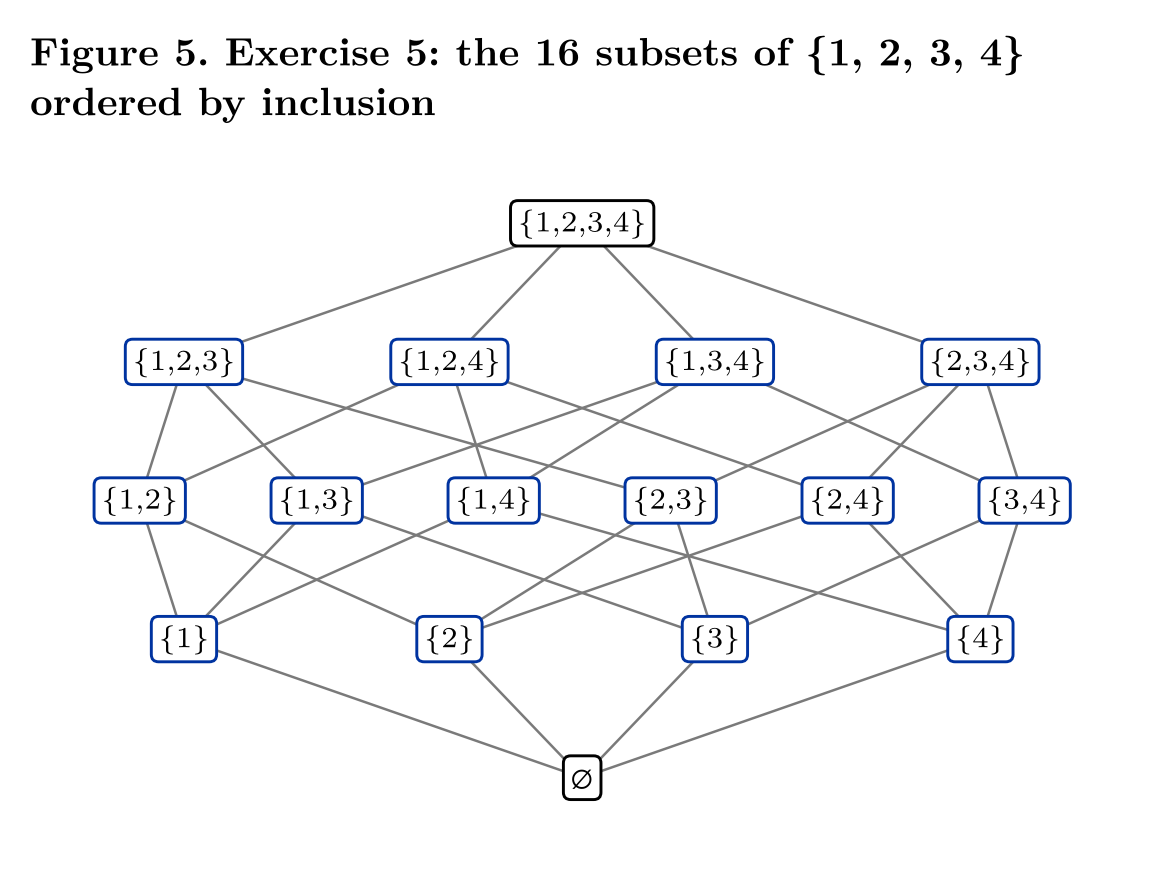

In [11]:
S = (1, 2, 3, 4)
subsets = power_set(S)
print(f"{len(subsets)} subsets; by size:", [sum(len(s) == k for s in subsets) for k in range(len(S) + 1)])


def label(s):
    return "$\\varnothing$" if not s else "{" + ",".join(str(v) for v in sorted(s)) + "}"


def draw_power_set():
    levels = {k: [s for s in subsets if len(s) == k] for k in range(len(S) + 1)}
    pos = {}
    for k, level in levels.items():
        for i, s in enumerate(level):
            pos[s] = ((i + 0.5) / len(level), k)
    fig, ax = plt.subplots(figsize=(4.75, 3.0))
    for a in subsets:
        for b in subsets:
            if len(b) == len(a) + 1 and a < b:
                may_touch(*ax.plot(*zip(pos[a], pos[b]), color=MUTED, lw=0.6, zorder=1))   # edges end at the labels
    for s, (px, py) in pos.items():
        ax.text(px, py, label(s), ha="center", va="center", fontsize=7, zorder=3,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=BLUE if 0 < len(s) < 4 else INK, lw=0.7))
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.5, 4.5)
    ax.set_axis_off()
    return fig


show_figure("fig5_power_set", draw_power_set,
            "Figure 5. Exercise 5: the 16 subsets of {1, 2, 3, 4} ordered by inclusion")

### Exercise 6

Let $A = \{1, 2\}$, $B = \{\{1\}, \{2\}\}$, $C = \{\{1\}, \{1, 2\}\}$, $D = \{\{1\}, \{2\}, \{1, 2\}\}$. Decide which
statements hold: (a) $A = B$, (b) $A \subseteq B$, (c) $A \subset C$, (d) $A \in C$, (e) $A \subset D$,
(f) $B \subset C$, (g) $B \subset D$, (h) $B \in D$, (i) $A \in D$.

**Solution.** The elements of $A$ are numbers; the elements of $B$, $C$ and $D$ are sets.

- (a) false: $A$ and $B$ have different elements.
- (b) false: $1 \in A$ but $1 \notin B$.
- (c) false: $1 \in A$ but $1 \notin C$.
- (d) true: $A = \{1, 2\}$ is an element of $C$.
- (e) false: $1 \in A$ but $1 \notin D$.
- (f) false: $\{2\} \in B$ but $\{2\} \notin C$.
- (g) true: $\{1\}$ and $\{2\}$ are elements of $D$, and $D$ has the further element $\{1, 2\}$.
- (h) false: $B = \{\{1\}, \{2\}\}$ is not one of the three elements of $D$.
- (i) true: $A = \{1, 2\}$ is an element of $D$.

In [12]:
A = frozenset({1, 2})
B = frozenset({frozenset({1}), frozenset({2})})
C = frozenset({frozenset({1}), frozenset({1, 2})})
D = frozenset({frozenset({1}), frozenset({2}), frozenset({1, 2})})
answers = {"(a) A = B": A == B, "(b) A ⊆ B": A <= B, "(c) A ⊂ C": is_proper_subset(A, C), "(d) A ∈ C": A in C,
           "(e) A ⊂ D": is_proper_subset(A, D), "(f) B ⊂ C": is_proper_subset(B, C),
           "(g) B ⊂ D": is_proper_subset(B, D), "(h) B ∈ D": B in D, "(i) A ∈ D": A in D}
for statement, value in answers.items():
    print(f"{statement}: {value}")

(a) A = B: False
(b) A ⊆ B: False
(c) A ⊂ C: False
(d) A ∈ C: True
(e) A ⊂ D: False
(f) B ⊂ C: False
(g) B ⊂ D: True
(h) B ∈ D: False
(i) A ∈ D: True


### Exercises 7–18: laws of the algebra of sets

In all proofs below we use the same principle: to prove an equality $X=Y$ we show both inclusions $X\subseteq Y$ and $Y\subseteq X$. To prove an inclusion $X\subseteq Y$ we take an arbitrary element $x\in X$ and show that $x\in Y$ by using the definitions of union, intersection, and difference.

#### Exercise 7: properties of set equality

##### (a) $\{a,a\}=\{a\}$

Let $x\in\{a,a\}$. Then $x=a$, hence $x\in\{a\}$. Conversely, if $x\in\{a\}$ then $x=a$, so $x\in\{a,a\}$. Therefore $\{a,a\}=\{a\}$.

##### (b) $\{a,b\}=\{b,a\}$

Let $x\in\{a,b\}$. Then $x=a$ or $x=b$, which means $x\in\{b,a\}$. The converse inclusion is proved in the same way. Hence $\{a,b\}=\{b,a\}$.

##### (c) $\{a\}=\{b,c\}$ if and only if $a=b=c$

Assume $\{a\}=\{b,c\}$. Since $b\in\{b,c\}=\{a\}$, we get $b=a$. Similarly, $c\in\{b,c\}=\{a\}$ implies $c=a$. Hence $a=b=c$. Conversely, if $a=b=c$, then $\{b,c\}=\{a,a\}=\{a\}$, so $\{a\}=\{b,c\}$.

#### Exercise 8: commutative laws

##### (a) $A\cup B=B\cup A$

Let $x\in A\cup B$. Then $x\in A$ or $x\in B$. This is equivalent to saying $x\in B$ or $x\in A$, hence $x\in B\cup A$. The converse inclusion is identical. Therefore $A\cup B=B\cup A$.

##### (b) $A\cap B=B\cap A$

Let $x\in A\cap B$. Then $x\in A$ and $x\in B$, which is the same as $x\in B$ and $x\in A$, hence $x\in B\cap A$. The converse is the same. Thus $A\cap B=B\cap A$.

#### Exercise 9: associative laws

##### (a) $A\cup(B\cup C)=(A\cup B)\cup C$

Let $x\in A\cup(B\cup C)$. Then $x\in A$ or ($x\in B$ or $x\in C$). This is equivalent to ($x\in A$ or $x\in B$) or $x\in C$, hence $x\in (A\cup B)\cup C$. The converse is obtained by reversing the reasoning.

##### (b) $A\cap(B\cap C)=(A\cap B)\cap C$

Let $x\in A\cap(B\cap C)$. Then $x\in A$ and ($x\in B$ and $x\in C$). This is equivalent to ($x\in A$ and $x\in B$) and $x\in C$, hence $x\in (A\cap B)\cap C$. The converse is analogous.

#### Exercise 10: distributive laws

##### (a) $A\cap(B\cup C)=(A\cap B)\cup(A\cap C)$

Let $x\in A\cap(B\cup C)$. Then $x\in A$ and ($x\in B$ or $x\in C$). Hence either $x\in A\cap B$ or $x\in A\cap C$, so $x\in (A\cap B)\cup(A\cap C)$. The converse follows by reversing the argument.

##### (b) $A\cup(B\cap C)=(A\cup B)\cap(A\cup C)$

Let $x\in A\cup(B\cap C)$. Then either $x\in A$, or $x\in B$ and $x\in C$. In both cases we get $x\in A\cup B$ and $x\in A\cup C$, hence $x\in (A\cup B)\cap(A\cup C)$. Conversely, if $x\in (A\cup B)\cap(A\cup C)$ and $x\notin A$, then $x\in B$ and $x\in C$, so $x\in B\cap C$, hence $x\in A\cup(B\cap C)$.

#### Exercise 11

##### (a) $A\cup A=A$

Let $x\in A\cup A$. Then $x\in A$ or $x\in A$, hence $x\in A$. Conversely, if $x\in A$ then $x\in A\cup A$. Thus $A\cup A=A$.

##### (b) $A\cap A=A$

Let $x\in A\cap A$. Then $x\in A$ and $x\in A$, so $x\in A$. Conversely, if $x\in A$ then $x\in A\cap A$. Hence $A\cap A=A$.

#### Exercise 12

##### (a) $A\subseteq A\cup B$

Let $x\in A$. Then $x\in A$ or $x\in B$, so $x\in A\cup B$. Hence $A\subseteq A\cup B$.

##### (b) $A\cap B\subseteq A$

Let $x\in A\cap B$. Then $x\in A$ and $x\in B$. In particular $x\in A$. Hence $A\cap B\subseteq A$.

#### Exercise 13

##### (a) $A\cup\varnothing=A$

Let $x\in A\cup\varnothing$. Then $x\in A$ or $x\in\varnothing$. The second is impossible, so $x\in A$. Conversely, if $x\in A$ then $x\in A\cup\varnothing$. Hence $A\cup\varnothing=A$.

##### (b) $A\cap\varnothing=\varnothing$

There is no $x$ such that $x\in\varnothing$. Hence there is no $x$ such that $x\in A\cap\varnothing$. Therefore $A\cap\varnothing=\varnothing$.

#### Exercise 14

##### (a) $A\cup(A\cap B)=A$

Let $x\in A\cup(A\cap B)$. Then either $x\in A$, or $x\in A\cap B$. In both cases $x\in A$. Conversely, if $x\in A$ then certainly $x\in A\cup(A\cap B)$. Hence $A\cup(A\cap B)=A$.

##### (b) $A\cap(A\cup B)=A$

Let $x\in A\cap(A\cup B)$. Then $x\in A$ and ($x\in A$ or $x\in B$). In particular $x\in A$. Conversely, if $x\in A$ then $x\in A\cap(A\cup B)$. Hence $A\cap(A\cup B)=A$.

#### Exercise 15

If $A\subseteq C$ and $B\subseteq C$, then $A\cup B\subseteq C$. Let $x\in A\cup B$. Then $x\in A$ or $x\in B$. In either case, since both are subsets of $C$, we get $x\in C$. Hence $A\cup B\subseteq C$.

#### Exercise 16

If $C\subseteq A$ and $C\subseteq B$, then $C\subseteq A\cap B$. Let $x\in C$. Then $x\in A$ and $x\in B$. Hence $x\in A\cap B$. Therefore $C\subseteq A\cap B$.

#### Exercise 17

##### (a) If $A\subset B$ and $B\subset C$, then $A\subset C$

Let $x\in A$. Since $A\subset B$, we have $x\in B$. Since $B\subset C$, we get $x\in C$. Hence $A\subseteq C$. Moreover $A\ne C$: if $A=C$, then $C\subseteq B$ and $B\subseteq C$, so $B=C$, which contradicts $B\subset C$. Hence $A\subset C$.

##### (b) If $A\subseteq B$ and $B\subseteq C$, then $A\subseteq C$

The proof is identical to part (a).

(c) Hence both $\subset$ and $\subseteq$ are transitive.

##### (d) If $x\in A$ and $A\subseteq B$, then $x\in B$

This follows directly from the definition of subset.

##### (e) If $x\in A$ and $A\in B$, it does not follow that $x\in B$

Elements of elements need not be elements of the set itself: for $A=\{1\}$ and $B=\{\{1\}\}$ we have $1\in A$ and $A\in B$, but $1\notin B$.

#### Exercise 18

$A-(B\cap C)=(A-B)\cup(A-C)$. Let $x\in A-(B\cap C)$. Then $x\in A$ and $x\notin B\cap C$, which means $x\notin B$ or $x\notin C$. Hence either $x\in A-B$ or $x\in A-C$, so $x\in (A-B)\cup(A-C)$. The converse is obtained by reversing the reasoning.

### Exercise 19

Let $\mathcal{F}$ be a class of sets. Prove:

$$
B-\bigcup_{A\in\mathcal{F}}A=\bigcap_{A\in\mathcal{F}}(B-A)
$$

and

$$
B-\bigcap_{A\in\mathcal{F}}A=\bigcup_{A\in\mathcal{F}}(B-A).
$$

#### Proof of $B-\bigcup_{A\in\mathcal{F}}A=\bigcap_{A\in\mathcal{F}}(B-A)$

Let $x\in B-\bigcup_{A\in\mathcal{F}}A$. Then $x\in B$ and $x\notin \bigcup_{A\in\mathcal{F}}A$. The second statement means that for every $A\in\mathcal{F}$ we have $x\notin A$. Hence for every $A\in\mathcal{F}$ we have $x\in B$ and $x\notin A$, which means $x\in B-A$. Since this holds for every $A\in\mathcal{F}$, we get $x\in\bigcap_{A\in\mathcal{F}}(B-A)$. Therefore $B-\bigcup_{A\in\mathcal{F}}A\subseteq \bigcap_{A\in\mathcal{F}}(B-A)$.

Conversely, let $x\in\bigcap_{A\in\mathcal{F}}(B-A)$. Then for every $A\in\mathcal{F}$ we have $x\in B-A$, so $x\in B$ and $x\notin A$. In particular $x\notin\bigcup_{A\in\mathcal{F}}A$. Hence $x\in B-\bigcup_{A\in\mathcal{F}}A$. This shows $\bigcap_{A\in\mathcal{F}}(B-A)\subseteq B-\bigcup_{A\in\mathcal{F}}A$, and the equality follows.

#### Proof of $B-\bigcap_{A\in\mathcal{F}}A=\bigcup_{A\in\mathcal{F}}(B-A)$

Let $x\in B-\bigcap_{A\in\mathcal{F}}A$. Then $x\in B$ and $x\notin \bigcap_{A\in\mathcal{F}}A$. The second statement means there exists some $A_0\in\mathcal{F}$ such that $x\notin A_0$. Hence $x\in B$ and $x\notin A_0$, so $x\in B-A_0$. Therefore $x\in\bigcup_{A\in\mathcal{F}}(B-A)$. This gives $B-\bigcap_{A\in\mathcal{F}}A\subseteq \bigcup_{A\in\mathcal{F}}(B-A)$.

Conversely, let $x\in\bigcup_{A\in\mathcal{F}}(B-A)$. Then there exists some $A_0\in\mathcal{F}$ such that $x\in B-A_0$, so $x\in B$ and $x\notin A_0$. Hence $x\notin\bigcap_{A\in\mathcal{F}}A$, and therefore $x\in B-\bigcap_{A\in\mathcal{F}}A$. This proves the reverse inclusion and the equality follows.

### Exercise 20

#### (a) One formula is always right and the other is sometimes wrong

(i) $A-(B-C)=(A-B)\cup C$

(ii) $A-(B\cup C)=(A-B)-C$

##### Claim: (ii) is always true

Let $x\in A-(B\cup C)$. Then $x\in A$ and $x\notin B\cup C$, which means $x\notin B$ and $x\notin C$. Hence $x\in A-B$, and also $x\notin C$, so $x\in (A-B)-C$. Therefore $A-(B\cup C)\subseteq (A-B)-C$.

Conversely, let $x\in (A-B)-C$. Then $x\in A-B$ and $x\notin C$, so $x\in A$, $x\notin B$, and $x\notin C$. Hence $x\notin B\cup C$, so $x\in A-(B\cup C)$. Therefore $(A-B)-C\subseteq A-(B\cup C)$, and (ii) holds.

##### Claim: (i) is not always true (counterexample)

Take $A=\{1\}$, $B=\varnothing$, $C=\{2\}$. Then $B-C=\varnothing$, so

$$
A-(B-C)=A-\varnothing=\{1\}.
$$

But

$$
(A-B)\cup C=(\{1\}-\varnothing)\cup\{2\}=\{1,2\}.
$$

So (i) fails in this case.

#### (b) Condition for (i) to be always right

We simplify the left side:

$$
A-(B-C)=A-(B\cap C^c)=A\cap (B\cap C^c)^c=A\cap(B^c\cup C)=(A\cap B^c)\cup(A\cap C)=(A-B)\cup(A\cap C).
$$

So (i) becomes:

$$
(A-B)\cup(A\cap C)=(A-B)\cup C.
$$

This holds exactly when $A\cap C=C$, which is equivalent to $C\subseteq A$.

So a necessary and sufficient condition for (i) to be always true is:

$$
C\subseteq A.
$$

The code checks both claims on every triple of subsets of $U = \{1, 2, 3, 4\}$ ($16^3 = 4{,}096$ triples): (ii) always
holds, and (i) holds exactly for the triples with $C \subseteq A$.

In [13]:
U_SUBSETS = power_set({1, 2, 3, 4})
triples = list(product(U_SUBSETS, repeat=3))
ii_always = all(A - (B | C) == (A - B) - C for A, B, C in triples)
i_iff = all((A - (B - C) == (A - B) | C) == (C <= A) for A, B, C in triples)
print(f"(ii) A - (B ∪ C) = (A - B) - C for all {len(triples):,} triples: {ii_always}")
print(f"(i)  A - (B - C) = (A - B) ∪ C exactly when C ⊆ A, for all triples: {i_iff}")
A, B, C = {1}, set(), {2}
print(f"counterexample A = {roster(A)}, B = ∅, C = {roster(C)}: A - (B - C) = {roster(A - (B - C))}, "
      f"(A - B) ∪ C = {roster((A - B) | C)}")

(ii) A - (B ∪ C) = (A - B) - C for all 4,096 triples: True
(i)  A - (B - C) = (A - B) ∪ C exactly when C ⊆ A, for all triples: True
counterexample A = {1}, B = ∅, C = {2}: A - (B - C) = {1}, (A - B) ∪ C = {1, 2}


## Summary and transition to Part 3

Exercises 1–6 wrote sets in roster notation, compared them by inclusion and separated membership ($\in$) from
inclusion ($\subseteq$), also for sets whose elements are sets; Exercise 5 listed the 16 subsets of a four-element set.
Exercises 7–18 proved the basic laws of the algebra of sets (commutative, associative, distributive and idempotent
laws, the laws for $\varnothing$, absorption, transitivity of inclusion and, in Exercise 18, a De Morgan law) by showing
inclusion in both directions, element by element; Exercise 19 extended two of them to families of sets. Exercise 20
separated an identity that always holds from one that holds only when $C \subseteq A$. The code confirmed both claims
on all triples of subsets of a four-element set; this is a check of the proofs, not a proof.

Part 3 of the Introduction, *A Set of Axioms for the Real-Number System*, uses this language to state the axioms from
which the properties of the real numbers are derived.